# Lab 5 — Phần 2: Speaker identification & verification

**Dữ liệu → MFCC / enrollment / cosine → kết quả.** Run All chạy lại thuật toán trong `src`, không chỉ đọc kết quả lưu sẵn. AMI EN2009d: 3 người, mỗi người 4 enroll + 2 dev + 2 test; các lượt nói riêng biệt nhưng cùng một cuộc họp.

In [1]:
from pathlib import Path
import sys, os
ROOT = Path.cwd().resolve()
if not (ROOT/'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR',str(ROOT/'.cache/matplotlib'))
import matplotlib.pyplot as plt
from IPython.display import Audio, Markdown, display
from src.speaker_experiments import load_ami_speakers, run_speaker_experiment
from src.visualization import (plot_speaker_data, plot_speaker_pipeline,
                               plot_speaker_identification, plot_speaker_verification)
DATA = ROOT/'data/speaker_recognition/ami'
RESULTS = ROOT/'results/speaker_recognition'
FIGURES = ROOT/'results/figures/speaker_recognition'
FIGURES.mkdir(parents=True,exist_ok=True)
CONFIG = dict(n_mfcc=20)
plt.rcParams.update({'font.size':10})

### 1. Visualize dữ liệu

Đếm clip theo split, kiểm tra độ dài và waveform của một enrollment clip/người. Giữ biên độ thật. Preview 23 giây không dùng xây model/chọn tham số; phần 4 chạy demo đánh giá bổ sung trên chính đoạn này.

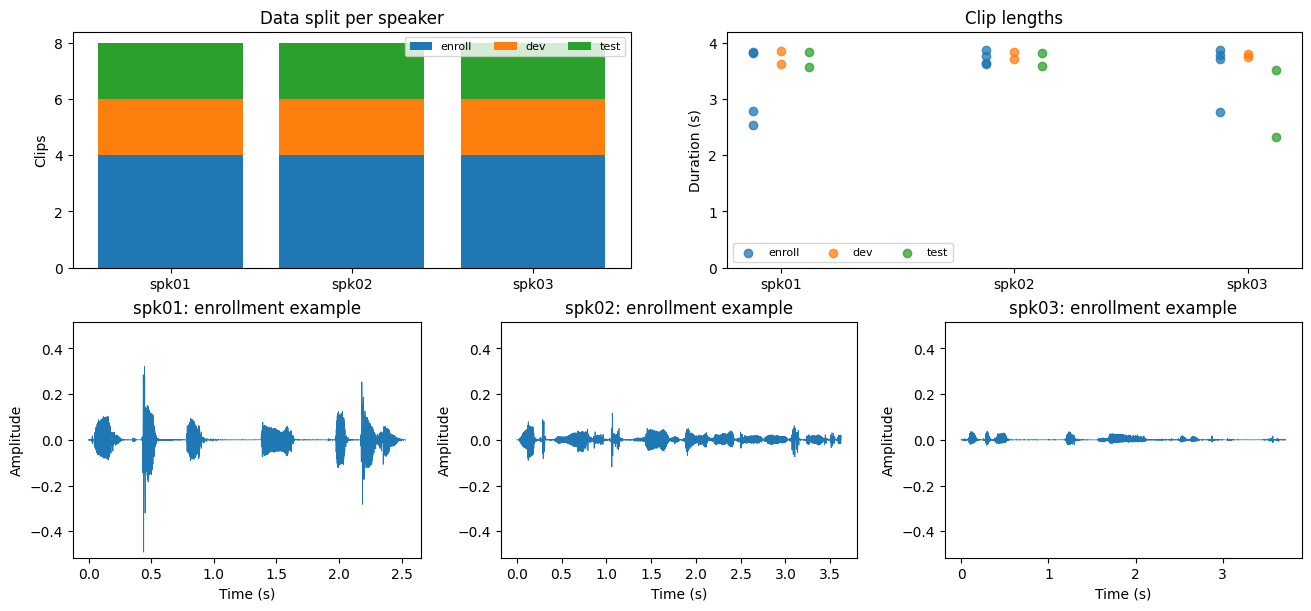

24 clip; duration 2.33–3.87s; mono 16 kHz.


In [2]:
dataset, inventory = load_ami_speakers(DATA)
samples = {speaker: (next(r for r in dataset if r['speaker']==speaker and r['split']=='enroll')['x'],16000)
           for speaker in sorted(inventory.speaker.unique())}
fig = plot_speaker_data(inventory,samples)
fig.savefig(FIGURES/'data_overview.png',dpi=150)
plt.show()
RESULTS.mkdir(parents=True,exist_ok=True)
inventory.to_csv(RESULTS/'data_inventory.csv',index=False)
print(f"{len(inventory)} clip; duration {inventory.duration.min():.2f}–{inventory.duration.max():.2f}s; mono 16 kHz.")


### 2. Pipeline và chạy phương pháp

Pre-emphasis 0,97 → Hann 25 ms / hop 10 ms / FFT 512 → 40 Mel filters → log-power → DCT → **20 MFCC**. Delta dùng cửa sổ 9 frame. Mean/std theo thời gian tạo vector **40 chiều** (MFCC) hoặc **80 chiều** (+delta), chuẩn hóa L2.

Mỗi model = trung bình 4 vector enroll rồi L2. Identification lấy cosine lớn nhất; verification accept khi score ≥ θ. Chỉ dùng **dev** để chọn MFCC/delta/CMN (accuracy, rồi margin) và θ gần cân bằng FAR–FRR; khóa trước test. So 1/2/4 enrollment trên dev, model test vẫn dùng 4.

Lệnh dưới thực sự chạy `speaker_embedding → enroll_speakers → cosine_scores → choose_threshold`; không dùng test chọn tham số.

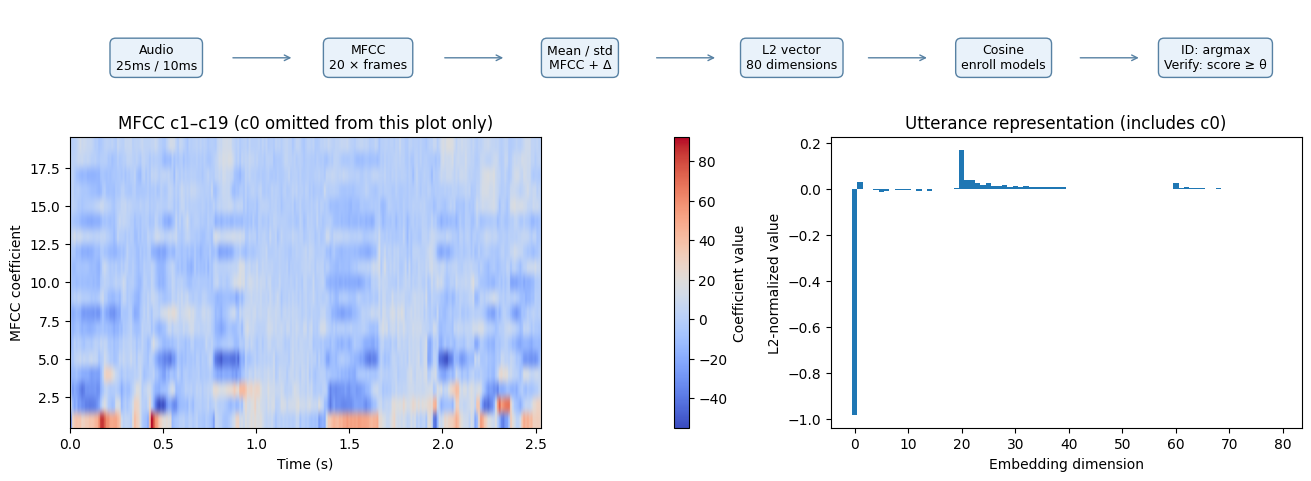

Dev chọn: MFCC+Δ; θ = 0.999142; 4 enroll/người.
Dev accuracy theo số enrollment: 1 clip: 66.7%; 2 clip: 100.0%; 4 clip: 100.0%


In [3]:
result = run_speaker_experiment(dataset,RESULTS,**CONFIG)
summary = result['summary']
example,sr = samples[result['speakers'][0]]
fig = plot_speaker_pipeline(example,sr,summary['features'])
fig.savefig(FIGURES/'method_pipeline.png',dpi=150)
plt.show()
print(f"Dev chọn: {summary['feature_name']}; θ = {summary['threshold']:.6f}; 4 enroll/người.")
print('Dev accuracy theo số enrollment: '+ '; '.join(
    f"{int(r.n_enroll)} clip: {r.dev_accuracy:.1%}" for r in result['enrollment'].itertuples()))

### 3. Visualize output — identification

Heatmap: cosine của 6 test clip với 3 model; ✓ là nhãn đúng. Confusion matrix cho thấy nhầm người nào. Ablation chỉ đánh giá trên dev. **Cosine gần 1 không phải xác suất đúng gần 100%**: MFCC c0 và các thống kê chung có thể chi phối hướng vector.

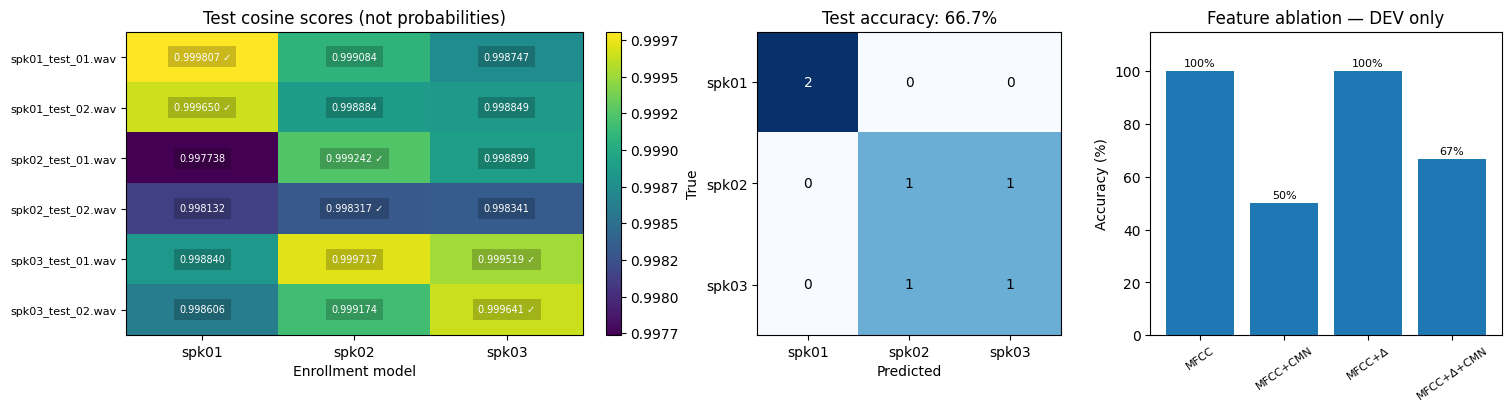

**Test: 4/6 đúng (66.7%).** Nhầm: spk02_test_02.wav: spk02 → spk03; spk03_test_01.wav: spk03 → spk02

Dev tốt nhất không CMN **100.0%**, có CMN **66.7%**. CMN bỏ mean MFCC nên có thể làm mất speaker cue của baseline này.

In [4]:
fig = plot_speaker_identification(result)
fig.savefig(FIGURES/'identification.png',dpi=150)
plt.show()
p = result['test_predictions']
errors = p[~p.correct]
display(Markdown(f"**Test: {int(p.correct.sum())}/{len(p)} đúng ({summary['test_accuracy']:.1%}).** "
    + ('Không có lỗi trên tập nhỏ này.' if errors.empty else 'Nhầm: '+ '; '.join(
        f"{r.file}: {r.true} → {r.predicted}" for r in errors.itertuples()))))
no_cmn = result['ablation'][~result['ablation'].cmn].dev_accuracy.max()
with_cmn = result['ablation'][result['ablation'].cmn].dev_accuracy.max()
display(Markdown(f"Dev tốt nhất không CMN **{no_cmn:.1%}**, có CMN **{with_cmn:.1%}**. "
                'CMN bỏ mean MFCC nên có thể làm mất speaker cue của baseline này.'))

**Verification:** genuine = đúng speaker/model; impostor = khác người. Chọn θ trên dev, báo cáo FAR/FRR trên test độc lập. Tập test chỉ có 6 genuine và 12 impostor trials; tỷ lệ lỗi thay đổi theo bước lớn, chưa đại diện hiệu năng thực tế.

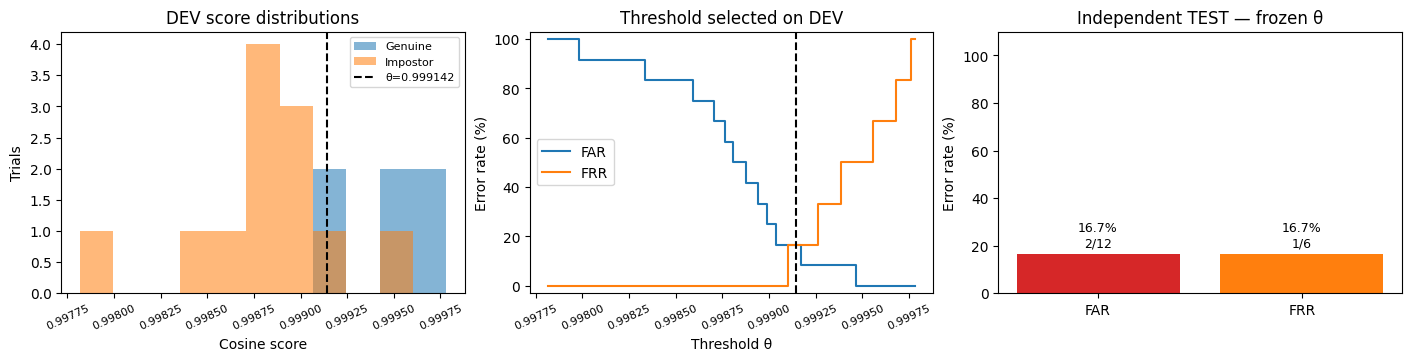

**Test FAR 16.7%** (2/12), **FRR 16.7%** (1/6). MFCC thống kê còn nhạy nội dung, âm lượng và âm phòng; cùng một phiên thu nên chưa đo được khả năng khác phiên.

Models, predictions, cosine scores, trials và threshold đã lưu tại results/speaker_recognition/.


In [5]:
fig = plot_speaker_verification(result)
fig.savefig(FIGURES/'verification.png',dpi=150)
plt.show()
v = summary['verification']
display(Markdown(f"**Test FAR {v['far']:.1%}** ({v['false_accepts']}/{v['impostor_trials']}), "
                f"**FRR {v['frr']:.1%}** ({v['false_rejects']}/{v['genuine_trials']}). "
                'MFCC thống kê còn nhạy nội dung, âm lượng và âm phòng; cùng một phiên thu nên chưa đo được khả năng khác phiên.'))
print('Models, predictions, cosine scores, trials và threshold đã lưu tại results/speaker_recognition/.')

### 4. Hội thoại 23 giây: ground truth vs dự đoán

Dùng **annotation thủ công** để biết ranh giới, không tự diarization. Bỏ vùng nói chồng và lượt ngắn <1 giây; không gộp nhiều người thành một embedding. Model MFCC/cosine đã enrollment và feature config giữ nguyên, vẫn so với **cả 3 model**, kể cả người không xuất hiện trong preview.

Preview không chồng khoảng thời gian enrollment/dev/test. Đây là demo bổ sung, không thay kết quả 6 test clip và không dùng điều chỉnh model/ngưỡng. Timeline và accuracy chỉ áp dụng trên các lượt đủ điều kiện.

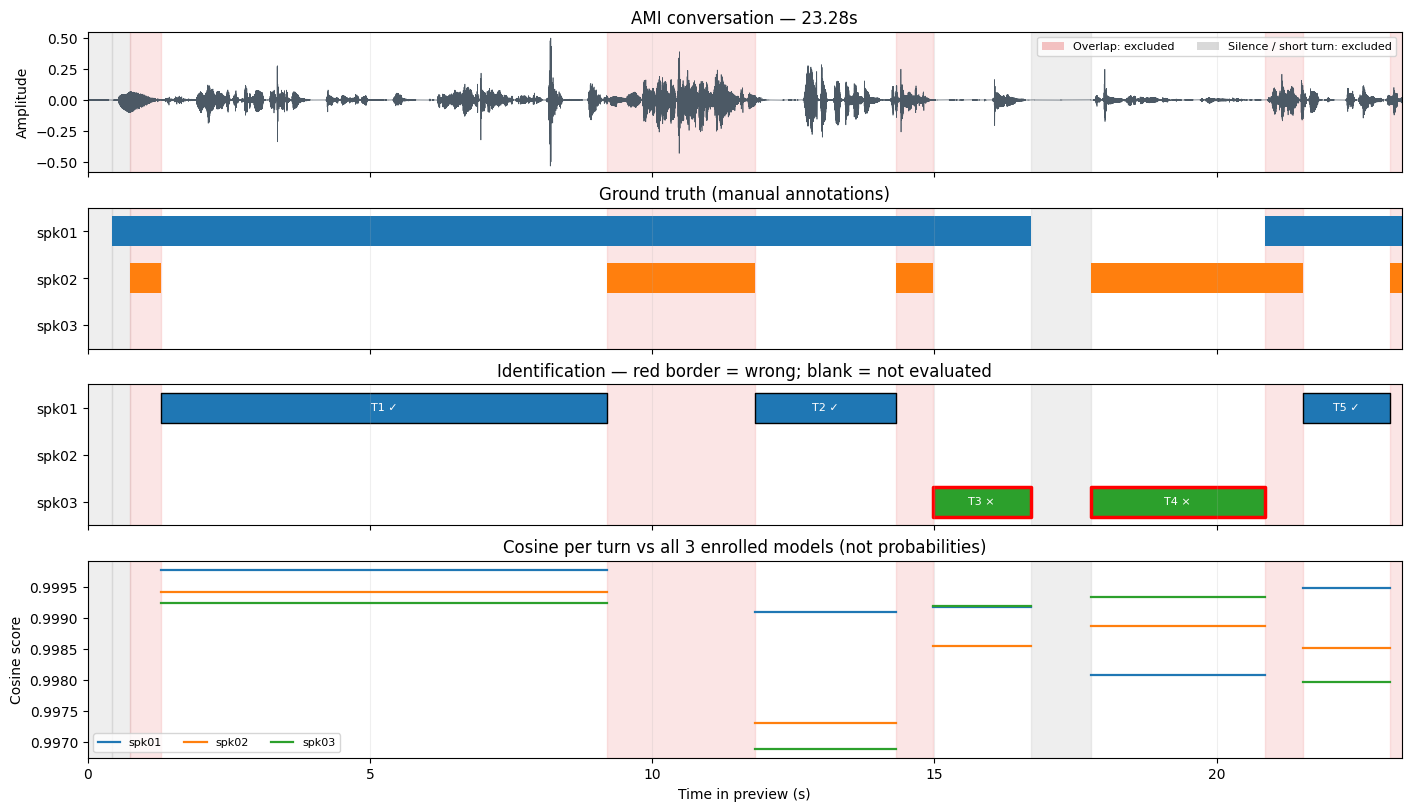

**Đúng 3/5 lượt (60.0%)**; đánh giá 16.77/23.28s (72.1%). Có 4.70s overlap được bỏ qua. Accuracy theo thời lượng đã đánh giá: **71.2%**; không tính silence/overlap/lượt ngắn vào mẫu số.

Nhầm: T3 (14.97–16.70s): spk01 → spk03; T4 (17.77–20.85s): spk02 → spk03. Score gần 1 vẫn có thể nhận dạng sai.

In [6]:
from src.speaker_experiments import evaluate_conversation
from src.visualization import plot_conversation_demo
conversation = evaluate_conversation(DATA,result['models'],summary['features'],RESULTS,min_duration=1.)
fig = plot_conversation_demo(conversation)
fig.savefig(FIGURES/'conversation_23s.png',dpi=150)
plt.show()
display(Audio(filename=str(DATA/'conversation_23s.wav')))
c = conversation['summary']
display(Markdown(
    f"**Đúng {c['correct_turns']}/{c['evaluated_turns']} lượt ({c['accuracy']:.1%})**; "
    f"đánh giá {c['evaluated_seconds']:.2f}/{c['duration_s']:.2f}s ({c['coverage']:.1%}). "
    f"Có {c['overlap_seconds']:.2f}s overlap được bỏ qua. "
    f"Accuracy theo thời lượng đã đánh giá: **{c['duration_weighted_accuracy']:.1%}**; "
    'không tính silence/overlap/lượt ngắn vào mẫu số.'))
errors = conversation['predictions'].query('not correct')
if not errors.empty:
    display(Markdown('Nhầm: '+ '; '.join(
        f"T{r.turn} ({r.start:.2f}–{r.end:.2f}s): {r.true} → {r.predicted}"
        for r in errors.itertuples())+'. Score gần 1 vẫn có thể nhận dạng sai.'))